In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from scipy.stats import skew
df = pd.read_csv(r"C:\Users\GY\Downloads\hotstar_viewer_engagement(in).csv")

In [97]:
df.head()

,user_id,content_title,genre,language,device,subscription_plan,city,age,watch_date,start_time,watch_duration,percent_completed,data_consumed_mb,rating,subtitles_used
0,HS10246,Bigg Boss House,Reality Show,Marathi,Smart TV,Mobile Plan,Chennai,33.0,8/4/2024,15:30,62,71.5,510.8,2.0,Yes
1,HS12530,Dil Ki Dastaan,Drama,Hindi,Mobile,Mobile Plan,Mumbai,23.0,4/6/2024,8:53 AM,59,65.0,504.6,NaN,No
2,HS11616,Prime News Hour,News,Tamil,Mobile,Free,Jaipur,30.0,21-01-2024,2:30 PM,15,15.0,68.2,2.0,NaN
3,HS12524,Dil Ki Dastaan,Drama,English,Smart TV,Mobile Plan,Mumbai,54.0,3/3/2024,1:30,34,60.8,259.3,NaN,No
4,HS12826,Mahabharat Katha,Devotional,Telugu,Smart TV,Mobile Plan,Pune,39.0,8/5/2024,5:49 AM,20,0.0,97.9,NaN,NaN


In [98]:
# first we analysic data
print("shape pf data set:-", df.shape)
print("information of data set:-", df.info())
print("describe of data data set:-",df.describe())

shape pf data set:- (800, 15)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   user_id            800 non-null    object 
 1   content_title      800 non-null    object 
 2   genre              800 non-null    object 
 3   language           800 non-null    object 
 4   device             771 non-null    object 
 5   subscription_plan  800 non-null    object 
 6   city               800 non-null    object 
 7   age                745 non-null    float64
 8   watch_date         800 non-null    object 
 9   start_time         800 non-null    object 
 10  watch_duration     776 non-null    object 
 11  percent_completed  800 non-null    float64
 12  data_consumed_mb   800 non-null    float64
 13  rating             370 non-null    float64
 14  subtitles_used     625 non-null    object 
dtypes: float64(4), object(11)
memory usage: 93.9

=======================================================================
### Task: 1 — Missing Values Clean

- Clean up the missing values. age, device, watch_duration, rating and subtitles_used all have gaps, but they're not the same kind of gap. Some genuinely weren't recorded (device), and some are missing because almost nobody fills them in (rating). Decide a separate, sensible treatment for each column instead of applying one rule to all of them, and explain your reasoning.

In [2]:
# First, let's check how many missing values are present
# in each column of the dataset.
df.isnull().sum()

user_id                0
content_title          0
genre                  0
language               0
device                29
subscription_plan      0
city                   0
age                   55
watch_date             0
start_time             0
watch_duration        24
percent_completed      0
data_consumed_mb       0
rating               430
subtitles_used       175
dtype: int64

In [171]:
# first we fill age with median 
df["age"] = df["age"].fillna(df["age"].median())

# Some sessions do not have device information.
# We replace the missing value with "Unknown" because
# we know that the device was not recorded.
df['device'] = df['device'].fillna('Unknown')

# Extract the numberic part from watch_duration
df["watch_duration"] = pd.to_numeric(
    df["watch_duration"],errors="coerce"
)
print(df["watch_duration"].median())

# Fill missing watch duration with the median value
df['watch_duration'] = df['watch_duration'].fillna(
    df['watch_duration'].median()
)

# Confirm that watch_duration has no missing values
df['watch_duration'].isnull().sum()

38.0


np.int64(0)

In [169]:
#check missing value in device
df["device"].isnull().sum()

np.int64(0)

In [170]:
# watch duration
# Check the data type of watch_duration
print(df["watch_duration"].dtype)

float64


In [158]:
# Convert rating column to object so that we can store
# "Not Rated" along with numerical ratings

df["rating"] = df["rating"].astype(object)

# Replace missing ratings with "Not Rated"
df["rating"] = df["rating"].fillna("Not Rated")

In [110]:
# Check missing values in rating
df["rating"].isnull().sum()

np.int64(0)

In [112]:
# Check how many subtitle values are missing
df["subtitles_used"].isnull().sum()

np.int64(175)

In [113]:
df["subtitles_used"] = df["subtitles_used"].fillna("Not Recorded")

In [114]:
# Check the different values present in the column
df["subtitles_used"].value_counts()

subtitles_used
Yes             325
No              300
Not Recorded    175
Name: count, dtype: int64

In [117]:
df.head(10)

,user_id,content_title,genre,language,device,subscription_plan,city,age,watch_date,start_time,watch_duration,percent_completed,data_consumed_mb,rating,subtitles_used
0,HS10246,Bigg Boss House,Reality Show,Marathi,Smart TV,Mobile Plan,Chennai,33.0,8/4/2024,15:30,62.0,71.5,510.8,2.0,Yes
1,HS12530,Dil Ki Dastaan,Drama,Hindi,Mobile,Mobile Plan,Mumbai,23.0,4/6/2024,8:53 AM,59.0,65.0,504.6,Not Rated,No
2,HS11616,Prime News Hour,News,Tamil,Mobile,Free,Jaipur,30.0,21-01-2024,2:30 PM,15.0,15.0,68.2,2.0,Not Recorded
3,HS12524,Dil Ki Dastaan,Drama,English,Smart TV,Mobile Plan,Mumbai,54.0,3/3/2024,1:30,34.0,60.8,259.3,Not Rated,No
4,HS12826,Mahabharat Katha,Devotional,Telugu,Smart TV,Mobile Plan,Pune,39.0,8/5/2024,5:49 AM,20.0,0.0,97.9,Not Rated,Not Recorded
5,HS11028,IPL: MI vs CSK,Cricket,Marathi,Tablet,Super Plan,Indore,48.0,12/1/2024,10:15 AM,33.0,71.7,133.6,Not Rated,Yes
6,HS12308,Business Today,News,Tamil,Unknown,Premium Plan,Bengaluru,21.0,10/2/2024,3:45 PM,735.0,92.2,3885.6,4.0,No
7,HS12843,The Laughter Club,Comedy,English,Laptop,Free,Hyderabad,15.0,3/2/2024,13:00,52.0,43.1,414.2,Not Rated,Not Recorded
8,HS11899,IPL: KKR vs SRH,Cricket,Hindi,Smart TV,Free,Delhi,13.0,10/4/2024,17:15,41.0,62.7,242.9,2.0,No
9,HS12271,Undercover,Thriller,Hindi,Smart TV,Premium Plan,Pune,40.0,20-04-2024,22:00,29.0,95.0,217.1,Not Rated,No


#### Missing Values:
I handled each missing-value column separately instead of using one method for all columns. Device and subtitles were marked as "Unknown/Not Recorded" because their actual values were not available. Rating was marked as "Not Rated" because a missing rating does not mean an average rating. Watch duration was filled using the median because it is a numerical variable. Age was kept missing because the actual age of those users is unknown.

=======================================================================
### Task 2 — Duplicate Sessions
- Find and remove the duplicate sessions. There are exact duplicate rows from the double-fire tracking bug, and a smaller set of near-duplicates where the same user/content/date shows up twice with only the device changed (looks like a re-login). Handle both cases and report how many rows you removed and why you're confident they're duplicates and not just two genuinely separate sessions. 

In [ ]:
# Total duplicated rows
df.duplicated().sum()

np.int64(35)

In [122]:
df = df.drop_duplicates()

In [ ]:
# Now removing near duplicates 

cols_without_device = [
    col for col in df.columns
    if col != "device"
]

near_duplicates = df[
    df.duplicated(subset=cols_without_device, keep=False)
]

near_duplicates[
    ["user_id","content_title" , "watch_date" , "device",x  
     "start_time" , "watch_duration" , "percent_completed"]
]

,user_id,content_title,watch_date,device,start_time,watch_duration,percent_completed
50,HS10466,Baahubali Reprise,5-Jan-24,Smart TV,11:30,25.0,100.0
58,HS11469,Undercover,15-01-2024,Smart TV,8:57 AM,17.0,33.3
82,HS12690,Election Special,22-03-2024,Laptop,22:15,49.0,30.9
109,HS12512,Vikram,17-06-2024,Laptop,9:15 AM,17.0,50.8
115,HS11036,IPL: DC vs PBKS,2-Jan-24,Mobile,7:13 AM,74.0,77.7
181,HS12503,Kantara,7/6/2024,Laptop,9:30 PM,57.0,100.0
183,HS12521,Prime News Hour,3/6/2024,Smart TV,5:27,38.0,70.9
186,HS12521,Prime News Hour,3/6/2024,Mobile,5:27,38.0,70.9
201,HS10559,Zindagi Gulzar Hai,28-03-2024,Tablet,9:15 AM,26.0,47.5
224,HS10466,Baahubali Reprise,5-Jan-24,Mobile,11:30,25.0,100.0


In [126]:
df = df.drop_duplicates(
    subset=cols_without_device,
    keep='first'
)
# Final verification
print("Final rows:", len(df))
print("Exact duplicates:", df.duplicated().sum())

Final rows: 750
Exact duplicates: 0


#### Duplicate Sessions:
I first removed 35 exact duplicate rows because all their values were identical. Then I identified 15 near-duplicate session pairs where the same user watched the same content on the same date with identical session details but a different device. These were treated as duplicate tracking/re-login records, so one record from each pair was retained

### Task : 2 - Detect & Treat Outliers
Detect and treat the outliers in watch_duration and age. watch_duration has some negative values and a few sessions that run into the hundreds of minutes. age has a few entries that clearly can't be real. Use appropriate methods (IQR/boxplots, or reasonable business limits like ‘no single episode session realistically runs 10+ hours’) to flag these, then decide whether to cap, drop or correct them – and say which you chose and why

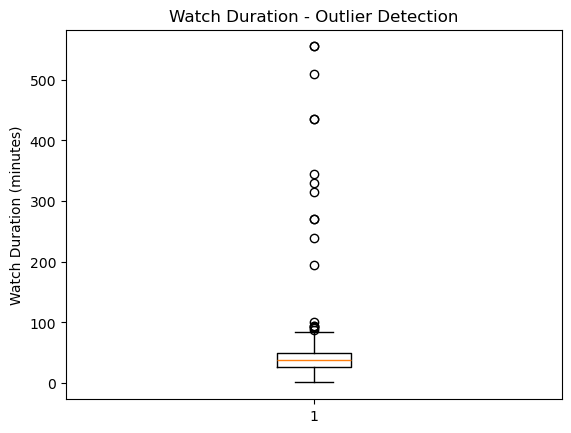

In [154]:
# use box plot 

# Boxplot to identify unusual watch duration values

plt.boxplot(df["watch_duration"].dropna())
plt.title("Watch Duration - Outlier Detection")
plt.ylabel("Watch Duration (minutes)")
plt.show()

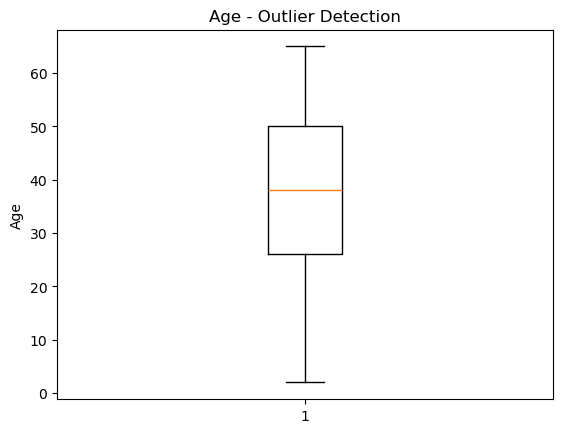

In [155]:
# Boxplot to identify unusual age values

plt.boxplot(df["age"].dropna())
plt.title("Age - Outlier Detection")
plt.ylabel("Age")
plt.show()

In [156]:
# Remove unrealistic watch duration values

df.loc[df["watch_duration"] < 0, "watch_duration"] = pd.NA
df.loc[df["watch_duration"] > 600, "watch_duration"] = pd.NA

# Remove unrealistic age values

df.loc[df["age"] > 100, "age"] = pd.NA

========================================================================
### Task : 4 -Fix Data Types
- Fix the data types. watch_duration is currently text with things like ‘min’ attached and won't compute correctly. Convert it to a proper numeric column. Do the same clean-up pass across age, rating and any other column that isn't in the type it should be, and confirm with .dtypes before moving on. 

In [3]:
# Check the data types of all columns
df.dtypes

user_id               object
content_title         object
genre                 object
language              object
device                object
subscription_plan     object
city                  object
age                  float64
watch_date            object
start_time            object
watch_duration        object
percent_completed    float64
data_consumed_mb     float64
rating               float64
subtitles_used        object
dtype: object

========================================================================
### Task : 5 -Standardise Date & Time
- Standardise the dates and times. watch_date is stored in at least three different formats. Parse it into one consistent datetime column. Combine it with start_time to get a full watch-timestamp, then pull out day of week, month and a weekend flag – you'll need these for the next task. 

In [143]:
# Convert different date formats into one standard date format

df["watch_date"] = pd.to_datetime(
    df["watch_date"],
    dayfirst=True,
    format="mixed"
)

In [145]:
# Check the different time formats present in start_time

df["start_time"].head(20)

0     15:30:00
1     08:53:00
2     14:30:00
3     01:30:00
4     05:49:00
5     10:15:00
6     15:45:00
7     13:00:00
8     17:15:00
9     22:00:00
10    18:06:00
11    05:30:00
12    13:30:00
13    09:00:00
14    11:00:00
15    13:43:00
16    09:00:00
17    01:15:00
18    16:45:00
19    11:30:00
Name: start_time, dtype: object

In [ ]:
# Check a few unique time values

df["start_time"].dropna().unique()[:20]

array([datetime.time(15, 30), datetime.time(8, 53), datetime.time(14, 30),
       datetime.time(1, 30), datetime.time(5, 49), datetime.time(10, 15),
       datetime.time(15, 45), datetime.time(13, 0), datetime.time(17, 15),
       datetime.time(22, 0), datetime.time(18, 6), datetime.time(5, 30),
       datetime.time(13, 30), datetime.time(9, 0), datetime.time(11, 0),
       datetime.time(13, 43), datetime.time(1, 15), datetime.time(16, 45),
       datetime.time(11, 30), datetime.time(17, 30)], dtype=object)

In [147]:
df.head()

,user_id,content_title,genre,language,device,subscription_plan,city,age,watch_date,start_time,watch_duration,percent_completed,data_consumed_mb,rating,subtitles_used
0,HS10246,Bigg Boss House,Reality Show,Marathi,Smart TV,Mobile Plan,Chennai,33.0,2024-04-08,15:30:00,62.0,71.5,510.8,2.0,Yes
1,HS12530,Dil Ki Dastaan,Drama,Hindi,Mobile,Mobile Plan,Mumbai,23.0,2024-06-04,08:53:00,59.0,65.0,504.6,Not Rated,No
2,HS11616,Prime News Hour,News,Tamil,Mobile,Free,Jaipur,30.0,2024-01-21,14:30:00,15.0,15.0,68.2,2.0,Not Recorded
3,HS12524,Dil Ki Dastaan,Drama,English,Smart TV,Mobile Plan,Mumbai,54.0,2024-03-03,01:30:00,34.0,60.8,259.3,Not Rated,No
4,HS12826,Mahabharat Katha,Devotional,Telugu,Smart TV,Mobile Plan,Pune,39.0,2024-05-08,05:49:00,20.0,0.0,97.9,Not Rated,Not Recorded


In [148]:
# Combine watch_date and start_time
# to create the complete watch timestamp

df["watch_timestamp"] = pd.to_datetime(
    df["watch_date"].astype(str) + " " +
    df["start_time"].astype(str)
)

In [149]:
# Check the result

df[["watch_date", "start_time", "watch_timestamp"]].head()

,watch_date,start_time,watch_timestamp
0,2024-04-08,15:30:00,2024-04-08 15:30:00
1,2024-06-04,08:53:00,2024-06-04 08:53:00
2,2024-01-21,14:30:00,2024-01-21 14:30:00
3,2024-03-03,01:30:00,2024-03-03 01:30:00
4,2024-05-08,05:49:00,2024-05-08 05:49:00


In [150]:
# Extract day of the week
df["day_of_week"] = df["watch_timestamp"].dt.day_name()

# Extract month
df["month"] = df["watch_timestamp"].dt.month_name()

# Identify weekends
df["is_weekend"] = df["watch_timestamp"].dt.dayofweek >= 5

In [172]:
df.dtypes

user_id                      object
content_title                object
genre                        object
language                     object
device                       object
subscription_plan            object
city                         object
age                         float64
watch_date           datetime64[ns]
start_time                   object
watch_duration              float64
percent_completed           float64
data_consumed_mb            float64
rating                       object
subtitles_used               object
watch_timestamp      datetime64[ns]
day_of_week                  object
month                        object
is_weekend                     bool
dtype: object

======================================================================
### Task : 6 — Build Derived Features
- Build 3-4 derived features. At minimum: an age_group bucket (e.g. teen/young adult/adult/senior), a prime_time flag for sessions starting between 7 PM and 11 PM, and a completion_bucket (e.g. dropped-off / partial / full) based on percent_completed. Add one more feature of your own if you can think of something useful for the content team. 

In [174]:
# ============================================================
# Create Derived Features
# ============================================================

# 1. Create age groups
df["age_group"] = pd.cut(
    df["age"],
    bins=[0,19,29,49,float("inf")],
    labels= ["Teen","Young Adult","Adult","Senior"]
)

# 2. Identify prime-time session
# Prime time is defined as sessions starting between 7 PM and 11 PM.
df["prime_time"] = (
    df["watch_timestamp"].dt.hour >=19
) & (
    df["watch_timestamp"].dt.hour <23
)
# 3. Create completion buckets
# Less than 25%  = Dropped-off
# 25% to less than 75% = Partial
# 75% or more = Full

df["completion_bucket"] = pd.cut(
    df["percent_completed"],
    bins=[-1, 24.99, 74.99, 100],
    labels=["Dropped-off", "Partial", "Full"]
)


# 4. Calculate data consumed per minute
# This can help the content/technical team understand
# how much data is consumed during a typical viewing minute.

df["data_per_minute"] = (
    df["data_consumed_mb"] / df["watch_duration"]
)

- Check the newly created features

In [177]:
df[
    [
        "age_group",
        "prime_time",
        "completion_bucket",
        "data_per_minute"
    ]
].head()

,age_group,prime_time,completion_bucket,data_per_minute
0,Adult,False,Partial,8.238710
1,Young Adult,False,Partial,8.552542
2,Adult,False,Dropped-off,4.546667
3,Senior,False,Partial,7.626471
4,Adult,False,Dropped-off,4.895000


========================================================================
### Task : 7 — Univariate Analysis
- Do a univariate analysis of the key numeric and categorical columns. Look at watch_duration, percent_completed, age and data_consumed_mb on their own – what's the typical session like, and what's the spread? Also check the split across genre, device and subscription_plan. A couple of sentences per column on what you notice is enough. 

1. Numerical Columns

In [184]:
# Summary of key numerical columns

df[[
    "watch_duration",
    "percent_completed",
    "age",
    "data_consumed_mb"
]].describe()

,watch_duration,percent_completed,age,data_consumed_mb
count,750.000000,750.000000,750.000000,750.00000
mean,43.656000,60.132933,38.141333,396.09280
std,47.782457,26.808396,15.086445,855.70298
min,1.000000,0.000000,2.000000,4.20000
25%,27.000000,41.625000,26.000000,139.70000
50%,38.000000,62.700000,38.000000,233.95000
75%,49.000000,80.475000,50.000000,350.90000
max,555.000000,100.000000,65.000000,9048.00000


2. Watch Duration

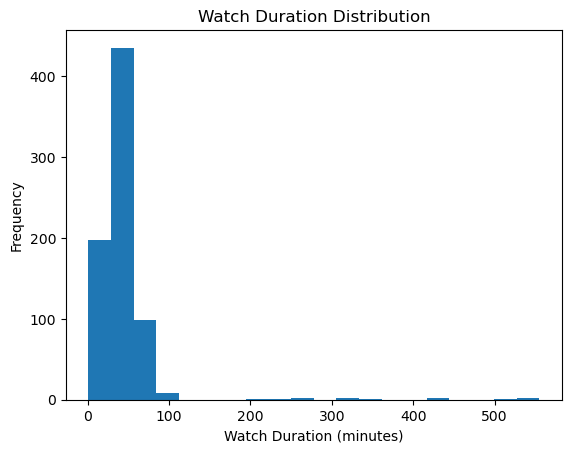

In [185]:
# Distribution of watch duration

df["watch_duration"].plot(
    kind="hist",
    bins=20,
    title="Watch Duration Distribution"
)

plt.xlabel("Watch Duration (minutes)")
plt.show()

3. Percent Completed

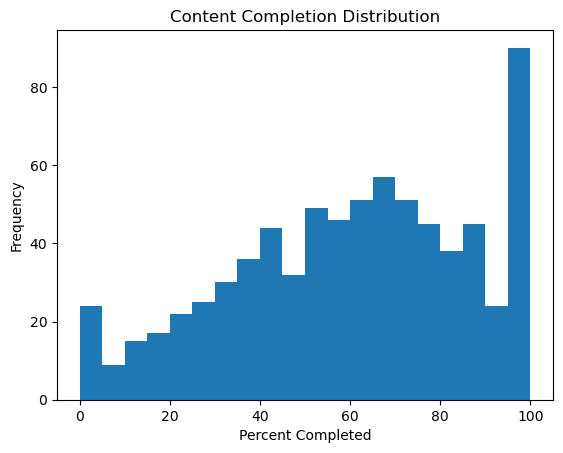

In [ ]:
# Distribution of content completion

df["percent_completed"].plot(
    kind="hist",
    bins=20,
    title="Content Completion Distribution"
    edgecolor=
)

plt.xlabel("Percent Completed")
plt.show()

4. Age

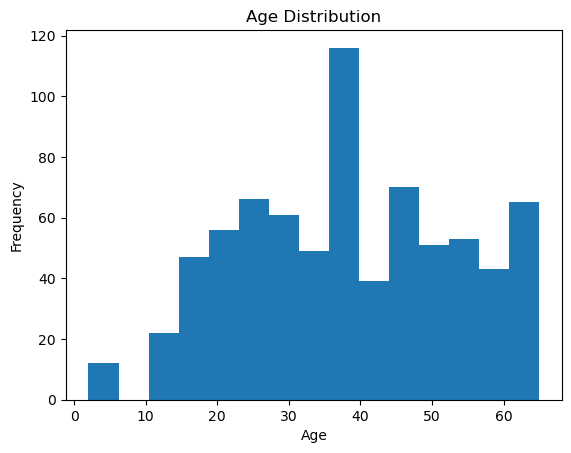

In [187]:
# Distribution of viewer age

df["age"].plot(
    kind="hist",
    bins=15,
    title="Age Distribution"
)

plt.xlabel("Age")
plt.show()

5. Data Consumed

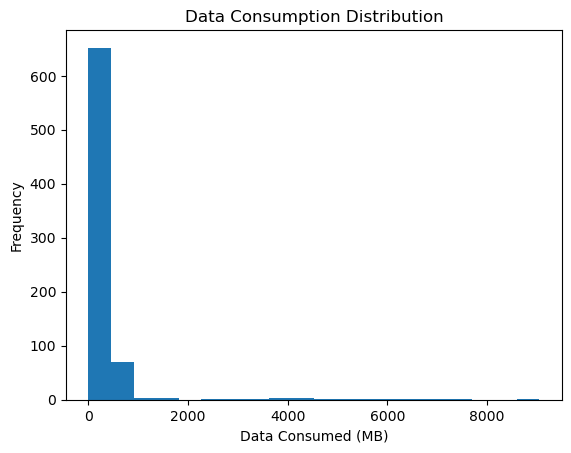

In [188]:
# Distribution of data consumption

df["data_consumed_mb"].plot(
    kind="hist",
    bins=20,
    title="Data Consumption Distribution"
)

plt.xlabel("Data Consumed (MB)")
plt.show()

6. Genre, Device & Subscription Plan

In [189]:
# Count sessions across important categorical columns

for col in ["genre", "device", "subscription_plan"]:
    print(f"\n{col}")
    print(df[col].value_counts())


genre
genre
Drama              97
Thriller           89
Devotional         86
Comedy             86
News               85
Regional Cinema    81
Reality Show       79
Cricket            79
Kids               68
Name: count, dtype: int64

device
device
Smart TV    241
Mobile      224
Laptop      137
Tablet      123
Unknown      25
Name: count, dtype: int64

subscription_plan
subscription_plan
Free            237
Mobile Plan     210
Super Plan      190
Premium Plan    113
Name: count, dtype: int64


- Reasoning:

Univariate analysis was performed to understand each important variable individually. For numerical columns such as watch_duration, percent_completed, age, and data_consumed_mb, descriptive statistics and distributions were used to understand their typical values and spread. For categorical columns such as genre, device, and subscription_plan, value counts were used to understand how sessions are distributed across different categories. This gives a basic understanding of viewer behaviour before moving to comparisons between multiple variables

======================================================================

### Task : 8 — Relationship Between Variables
- Explore relationships between variables. At minimum, check: does watch_duration differ by subscription_plan? Does percent_completed differ by device? Does genre affect rating? Use groupby summaries plus at least one visual for each comparison, and say what it means for the business, not just what the numbers are. 

1- Relationship Analysis

Average Watch Duration by Subscription Plan:
subscription_plan
Free            45.430380
Mobile Plan     48.371429
Premium Plan    36.460177
Super Plan      40.510526
Name: watch_duration, dtype: float64


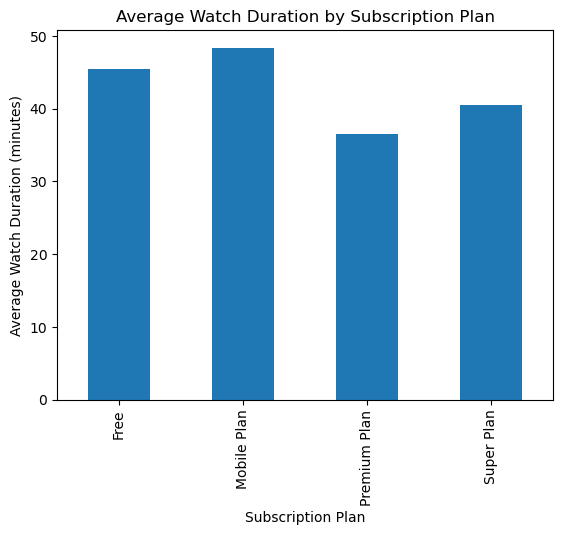

In [ ]:

# Watch duration by subscription plan
watch_by_plan = df.groupby("subscription_plan")["watch_duration"].mean()

print("Average Watch Duration by Subscription Plan:")
print(watch_by_plan)

watch_by_plan.plot(kind="bar", title="Average Watch Duration by Subscription Plan")
plt.xlabel("Subscription Plan")
plt.ylabel("Average Watch Duration (minutes)")
plt.show()


2-Percent completed by device


Average Completion by Device:
device
Laptop      65.526277
Mobile      60.879018
Smart TV    59.879253
Tablet      54.469919
Unknown     54.200000
Name: percent_completed, dtype: float64


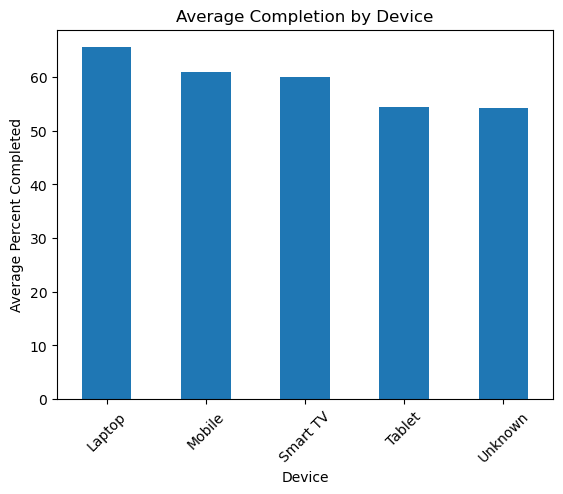

In [192]:
completion_by_device = df.groupby("device")["percent_completed"].mean()

print("\nAverage Completion by Device:")
print(completion_by_device)

completion_by_device.plot(kind="bar", title="Average Completion by Device")
plt.xlabel("Device")
plt.ylabel("Average Percent Completed")
plt.xticks(rotation=45)
plt.show()


3- Genre and rating


Average Rating by Genre:
genre
Comedy             2.950000
Cricket            2.828571
Devotional         2.840909
Drama              3.019608
Kids               3.031250
News               3.314286
Reality Show       2.709677
Regional Cinema    2.970588
Thriller           2.780488
Name: rating_numeric, dtype: float64


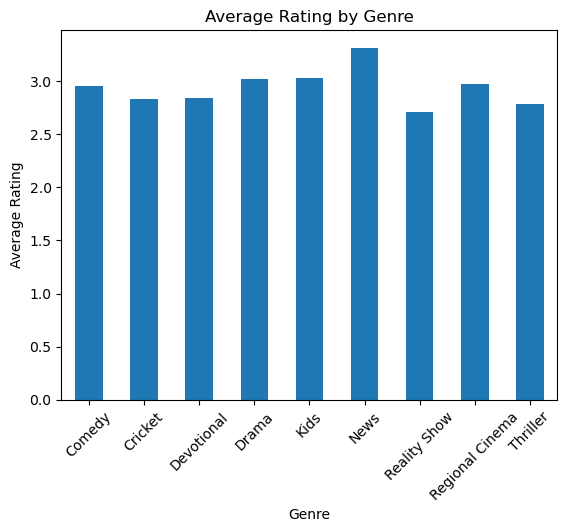

In [193]:
rating_numeric = pd.to_numeric(df["rating"], errors="coerce")

genre_rating = df.assign(
    rating_numeric=rating_numeric
).groupby("genre")["rating_numeric"].mean()

print("\nAverage Rating by Genre:")
print(genre_rating)

genre_rating.plot(kind="bar", title="Average Rating by Genre")
plt.xlabel("Genre")
plt.ylabel("Average Rating")
plt.xticks(rotation=45)
plt.show()

### Reasoning:
The analysis compares viewing behaviour across subscription plans, devices and genres. Average watch duration helps compare engagement across subscription plans, average completion shows how viewing differs by device, and average rating helps identify differences in viewer ratings across genres

======================================================================
### Task 9 — Histograms & Boxplots
- Plot histograms and boxplots for the main numeric columns. Show the distribution and spread of watch_duration, percent_completed and age – ideally a before/after pair for watch_duration so it's obvious the outlier treatment actually worked

- Distribution and Spread of Main Numerical Columns

1- Histograms

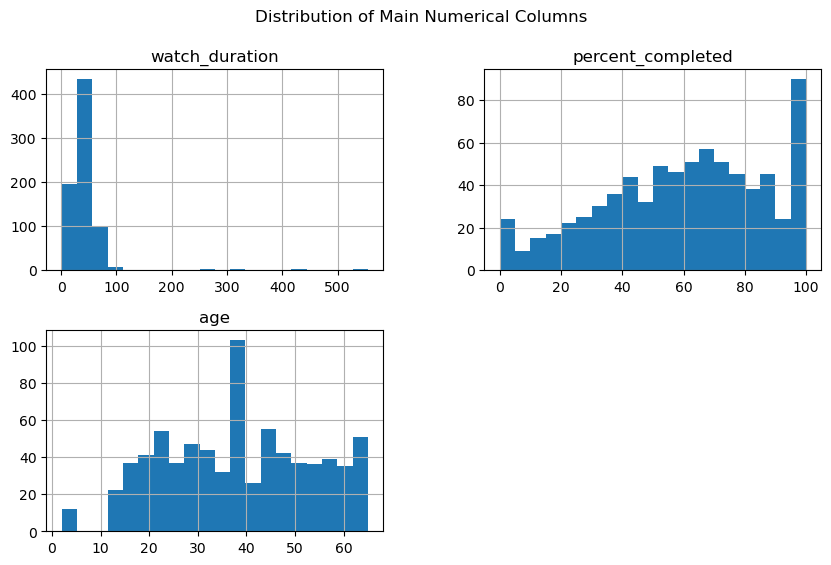

In [194]:
df[
    ["watch_duration",
     "percent_completed",
     "age"]
].hist(bins=20, figsize=(10, 6))

plt.suptitle("Distribution of Main Numerical Columns")
plt.show()

2- Boxplots

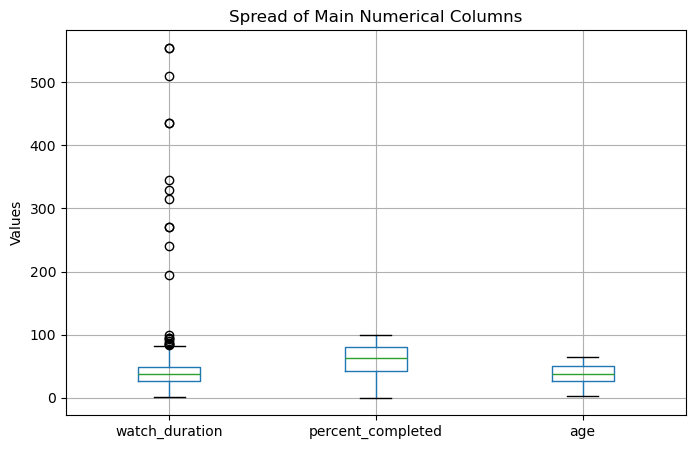

In [195]:
df[
    ["watch_duration",
     "percent_completed",
     "age"]
].boxplot(figsize=(8, 5))

plt.title("Spread of Main Numerical Columns")
plt.ylabel("Values")
plt.show()

### Reasoning:
Histograms show how the values are distributed, while boxplots show their spread and potential outliers. These plots also help verify whether the unusual values identified during the cleaning stage have been appropriately treated.

========================================================================
### Task 10 — Bar Charts & Line Chart
- Build bar charts and a line chart. Bar chart: top genres by total watch time or session count. Bar chart: average percent_completed by device. Line chart: how total watch time trends week over week (or month over month) across Jan-Jun 2024 – see if you can spot the IPL months in there

1- Top genres by session count

Top Genres by Session Count:
genre
Drama              97
Thriller           89
Devotional         86
Comedy             86
News               85
Regional Cinema    81
Reality Show       79
Cricket            79
Kids               68
Name: count, dtype: int64


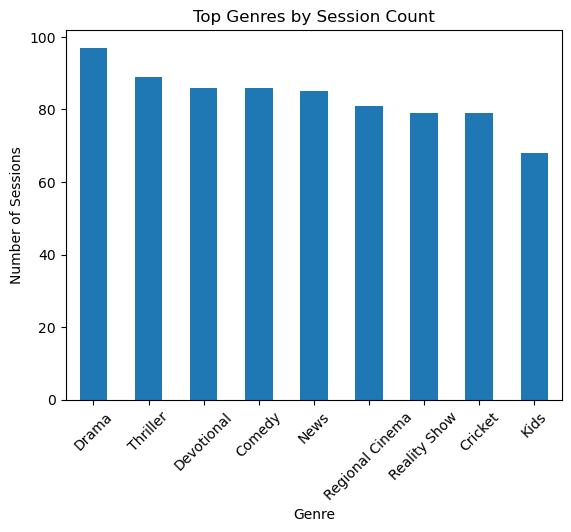

In [196]:
top_genres = df["genre"].value_counts().head(10)

print("Top Genres by Session Count:")
print(top_genres)

top_genres.plot(
    kind="bar",
    title="Top Genres by Session Count"
)

plt.xlabel("Genre")
plt.ylabel("Number of Sessions")
plt.xticks(rotation=45)
plt.show()


2- Average percent completed by device


Average Percent Completed by Device:
device
Laptop      65.526277
Mobile      60.879018
Smart TV    59.879253
Tablet      54.469919
Unknown     54.200000
Name: percent_completed, dtype: float64


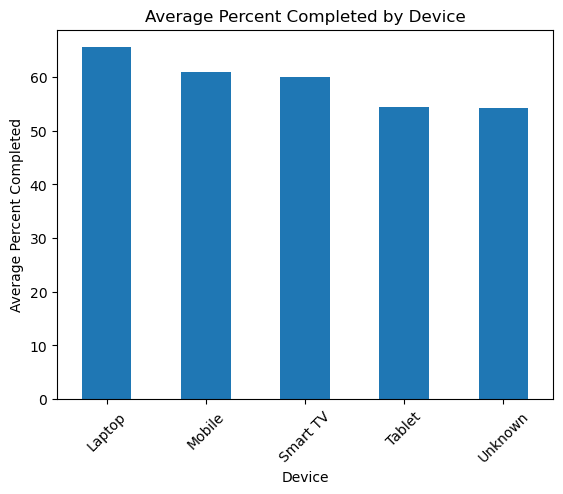

In [197]:
avg_completion = df.groupby("device")["percent_completed"].mean()

print("\nAverage Percent Completed by Device:")
print(avg_completion)

avg_completion.plot(
    kind="bar",
    title="Average Percent Completed by Device"
)

plt.xlabel("Device")
plt.ylabel("Average Percent Completed")
plt.xticks(rotation=45)
plt.show()

3- Weekly total watch time from January to June 2024

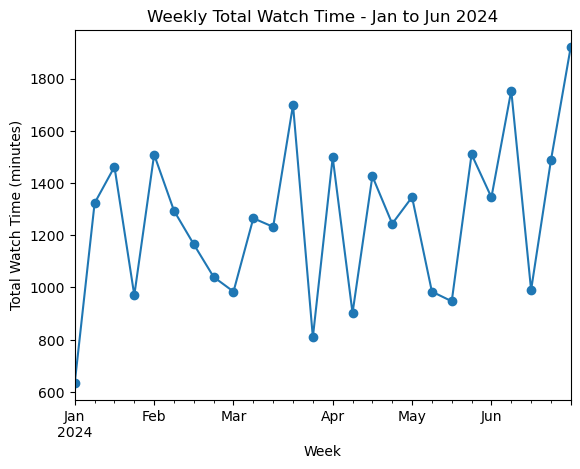

In [198]:
weekly_watch = (
    df[
        (df["watch_timestamp"] >= "2024-01-01") &
        (df["watch_timestamp"] < "2024-07-01")
    ]
    .set_index("watch_timestamp")["watch_duration"]
    .resample("W")
    .sum()
)

weekly_watch.plot(
    kind="line",
    marker="o",
    title="Weekly Total Watch Time - Jan to Jun 2024"
)

plt.xlabel("Week")
plt.ylabel("Total Watch Time (minutes)")
plt.show()

### Reasoning:
The genre bar chart identifies the most frequently viewed content categories, while the device comparison shows differences in content completion across viewing devices. The weekly line chart shows how total watch time changes from January to June 2024, which can help identify periods of increased viewing activity, including possible spikes around major sporting or entertainment events.

========================================================================
### Task 11 — Pair Plot
- Use a pair plot for a multivariate view. Pick 3-4 numeric columns (e.g. watch_duration, percent_completed, data_consumed_mb, age) and generate a pair plot, coloured by subscription_plan or device. Call out any pattern that stands out. 

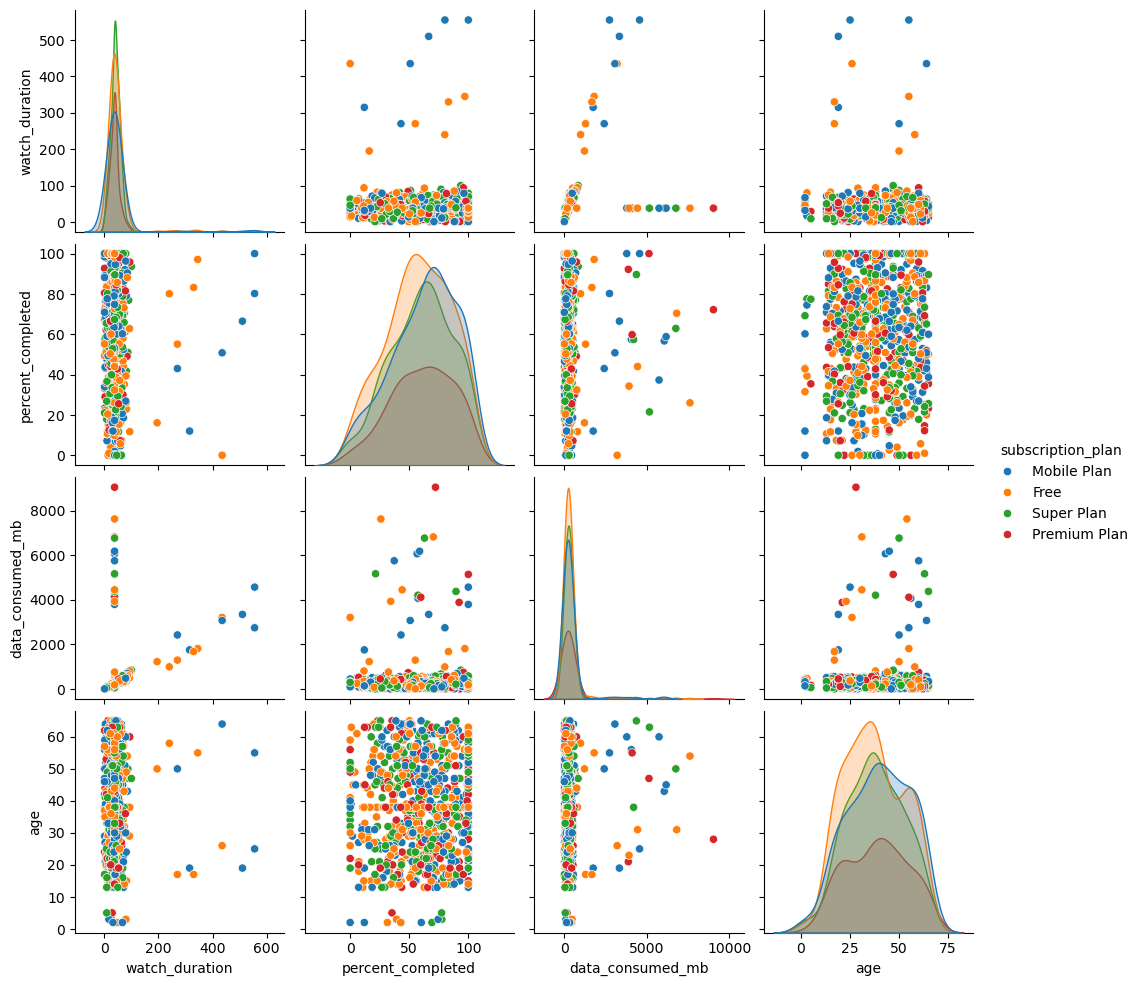

In [200]:
# ============================================================
# Multivariate Analysis - Pair Plot
# ============================================================

import seaborn as sns
import matplotlib.pyplot as plt

# Select important numerical columns
pair_data = df[
    [
        "watch_duration",
        "percent_completed",
        "data_consumed_mb",
        "age",
        "subscription_plan"
    ]
].dropna()

# Create pair plot
sns.pairplot(
    pair_data,
    vars=[
        "watch_duration",
        "percent_completed",
        "data_consumed_mb",
        "age"
    ],
    hue="subscription_plan"
)

plt.show()

### Reasoning:
The pair plot provides a multivariate view of the main numerical variables and shows how their relationships differ across subscription plans. It can help identify visible patterns, clusters or unusual combinations that may not be obvious when analysing each variable separately

======================================================================
### Task 12 — Final Findings Summary
Wrap up with a short findings’ summary. 3-5 bullet points a content strategy manager could actually act on – not ‘the data shows interesting patterns’, but specific things like which genre/device combo is under-performing or over-performing. Also note anywhere you had to make a judgement call while cleaning the data, since that affects how much the strategy team should trust the numbers. 

#### Final Findings Summary :
- Most viewing sessions have relatively short watch durations, while a small number of sessions have much longer durations. These extreme sessions should be investigated separately.
Content completion varies widely, with some users leaving content early and others watching almost the entire content.
Data consumption is mostly concentrated at lower levels, while a small number of sessions show very high data usage.
Viewing patterns overlap across subscription plans, so subscription plan alone does not clearly separate user behaviour.
The results can help the content team focus on content and devices associated with higher engagement and investigate unusually long sessions or high data consumption.
Data Cleaning Note

- During data cleaning, different types of missing and invalid values were handled according to their meaning rather than applying one rule to every column. Unrealistic watch durations and ages were treated as invalid, while genuinely missing or unrecorded values were handled separately. Therefore, the findings are based on the cleaned dataset and should be interpreted with these data-quality decisions in mind.